# Part 2 - Weekday Analysis and Sales Forecast (Jan 2020)
Extension of the pharma sales project. Questions:
1. On which day of the week is M01AE most often sold?
2. Top 3 drugs in Jan 2015, Jul 2016, Sep 2017 (with a check against known answers)
3. Which drug sold most on Mondays in 2017?
4. What might sales be in January 2020? (Linear, Polynomial, SVR and a Voting ensemble)

Needs `data/salesdaily.csv`. Monthly data is built from the daily file.

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.ensemble import VotingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

plt.rcParams['figure.figsize'] = (10, 5); plt.rcParams['axes.grid'] = True
os.makedirs('../outputs', exist_ok=True)

df = pd.read_csv('../data/salesdaily.csv')
df['datum'] = pd.to_datetime(df['datum'])
df = df.sort_values('datum').reset_index(drop=True)
drugs = [c for c in ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06'] if c in df.columns]
df['Year'] = df['datum'].dt.year
df['Month'] = df['datum'].dt.month
df['Weekday'] = df['datum'].dt.day_name()

## Q1 - Day of the week when M01AE is most often sold
Group by weekday, sum the sales, sort, and take the top row.

The second drug, M01AE, was most often sold on Sunday with the volume of 1384.94


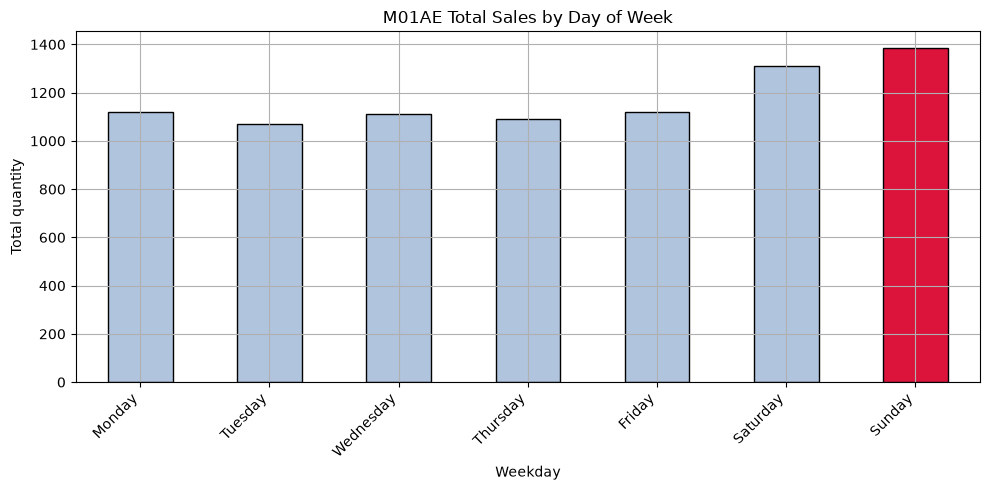

,Best day
M01AB,Saturday
M01AE,Sunday
N02BA,Tuesday
N02BE,Saturday
N05B,Wednesday
N05C,Friday
R03,Monday
R06,Saturday


In [2]:
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
wk = df.groupby('Weekday')['M01AE'].sum().reindex(day_order)
best_day = wk.idxmax()
print(f"The second drug, M01AE, was most often sold on {best_day} with the volume of {wk.max():.2f}")
wk.to_frame('Total M01AE').round(2).to_csv('outputs/p2_m01ae_by_weekday.csv')

ax = wk.plot(kind='bar', color=['crimson' if d == best_day else 'lightsteelblue' for d in wk.index], edgecolor='black')
ax.set_title('M01AE Total Sales by Day of Week'); ax.set_ylabel('Total quantity')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig('outputs/p2_m01ae_by_weekday.png', dpi=150); plt.show()

# Bonus: best day for every drug
best_all = df.groupby('Weekday')[drugs].sum().reindex(day_order).idxmax().to_frame('Best day')
display(best_all)

## Q2 - Top 3 drugs in selected months (reusable function)
A function avoids repeating code for each month.

In [3]:
def top3(year, month):
    sub = df[(df['Year'] == year) & (df['Month'] == month)]
    top = sub[drugs].sum().sort_values(ascending=False).head(3)
    print(f"Top 3 drugs by sale in {pd.Timestamp(year, month, 1):%B %Y}")
    for p, v in top.items():
        print(f"  Product: {p}, Volume sold: {round(v, 2)}")
    return top

for y, m in [(2015, 1), (2016, 7), (2017, 9)]:
    top3(y, m)

Top 3 drugs by sale in January 2015
  Product: N02BE, Volume sold: 1044.24
  Product: N05B, Volume sold: 463.0
  Product: R03, Volume sold: 177.25
Top 3 drugs by sale in July 2016
  Product: N02BE, Volume sold: 652.36
  Product: N05B, Volume sold: 240.0
  Product: M01AB, Volume sold: 194.53
Top 3 drugs by sale in September 2017
  Product: N02BE, Volume sold: 863.75
  Product: N05B, Volume sold: 223.0
  Product: R03, Volume sold: 139.0


### Validation
A published solution reports N02BE, N05B, R03 for Jan 2015 (values around 1044, 463, 177). If your numbers are close, your data loading and grouping are correct. Small differences can come from rounding or from using the monthly file instead of the daily file.

In [4]:
expected = {(2015,1): ['N02BE','N05B','R03'],
            (2016,7): ['N02BE','N05B','M01AB'],
            (2017,9): ['N02BE','N05B','R03']}
for (y, m), exp in expected.items():
    got = list(df[(df['Year']==y)&(df['Month']==m)][drugs].sum().sort_values(ascending=False).head(3).index)
    print(f"{y}-{m:02d}: got {got} | expected {exp} | {'MATCH' if got == exp else 'DIFFERENT'}")

2015-01: got ['N02BE', 'N05B', 'R03'] | expected ['N02BE', 'N05B', 'R03'] | MATCH
2016-07: got ['N02BE', 'N05B', 'M01AB'] | expected ['N02BE', 'N05B', 'M01AB'] | MATCH
2017-09: got ['N02BE', 'N05B', 'R03'] | expected ['N02BE', 'N05B', 'R03'] | MATCH


## Q3 - Which drug sold most on Mondays in 2017?
Filter to Mondays in 2017, sum each drug, and take the largest.

The drug most often sold on Mondays in 2017 is N02BE with the volume of 1160.56


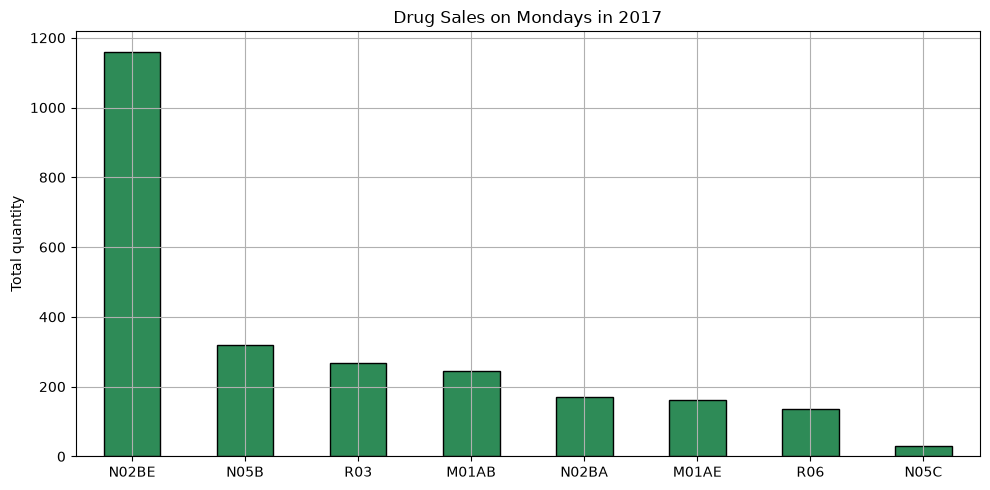

In [5]:
mon17 = df[(df['Year'] == 2017) & (df['Weekday'] == 'Monday')]
mon_tot = mon17[drugs].sum().sort_values(ascending=False)
print(f"The drug most often sold on Mondays in 2017 is {mon_tot.index[0]} with the volume of {mon_tot.iloc[0]:.2f}")
mon_tot.to_frame('Monday 2017 total').round(2).to_csv('outputs/p2_monday_2017.csv')

ax = mon_tot.plot(kind='bar', color='seagreen', edgecolor='black')
ax.set_title('Drug Sales on Mondays in 2017'); ax.set_ylabel('Total quantity')
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig('outputs/p2_monday_2017.png', dpi=150); plt.show()

## Q4 - Forecast sales for January 2020
**Method**
1. Build monthly totals from the daily data and drop October 2019 (incomplete).
2. Remove months where any drug has zero sales (simple cleaning).
3. Use month number `t` (0 = Jan 2014) as the only input; monthly sales as the target.
4. 70% train / 30% test split.
5. Fit Linear, Polynomial (degree 3) and SVR, then combine them with a Voting Regressor (average of the three).
6. Predict `t` for January 2020 and score each model with R² and RMSE on the test set.

In [6]:
product = 'M01AE'   # change to any drug code to repeat for other products

monthly = df.set_index('datum')[drugs].resample('MS').sum()
monthly = monthly[monthly.index < '2019-10-01']            # drop incomplete October 2019
monthly['t'] = np.arange(len(monthly))                      # month index (Jan 2014 = 0)
clean = monthly[(monthly[drugs] > 0).all(axis=1)]           # remove months with any zero
print(f'Months kept: {len(clean)} of {len(monthly)}')

target_t = (2020 - 2014) * 12 + (1 - 1)                     # Jan 2020 -> index 72
X = clean[['t']].values; y = clean[product].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

models = {
    'Linear': make_pipeline(LinearRegression()),
    'Polynomial (deg 3)': make_pipeline(PolynomialFeatures(3), StandardScaler(), LinearRegression()),
    'SVR': make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100, gamma='scale')),
}
models['Voting ensemble'] = VotingRegressor([(k, v) for k, v in list(models.items())])

rows = []
for name, mdl in models.items():
    mdl.fit(X_train, y_train)
    pred_test = mdl.predict(X_test)
    rows.append({'Model': name,
                 'R2 (test)': round(r2_score(y_test, pred_test), 3),
                 'RMSE (test)': round(np.sqrt(mean_squared_error(y_test, pred_test)), 2),
                 f'Predicted {product} Jan 2020': round(float(mdl.predict([[target_t]])[0]), 1)})
regResults = pd.DataFrame(rows).set_index('Model')
regResults.to_csv('outputs/p2_forecast_results.csv')
display(regResults)

Months kept: 69 of 69


,R2 (test),RMSE (test),Predicted M01AE Jan 2020
Model,,,
Linear,-0.040,12.59,116.7
Polynomial (deg 3),0.382,9.70,114.3
SVR,0.043,12.08,89.6
Voting ensemble,0.320,10.18,106.9


### Plot the models

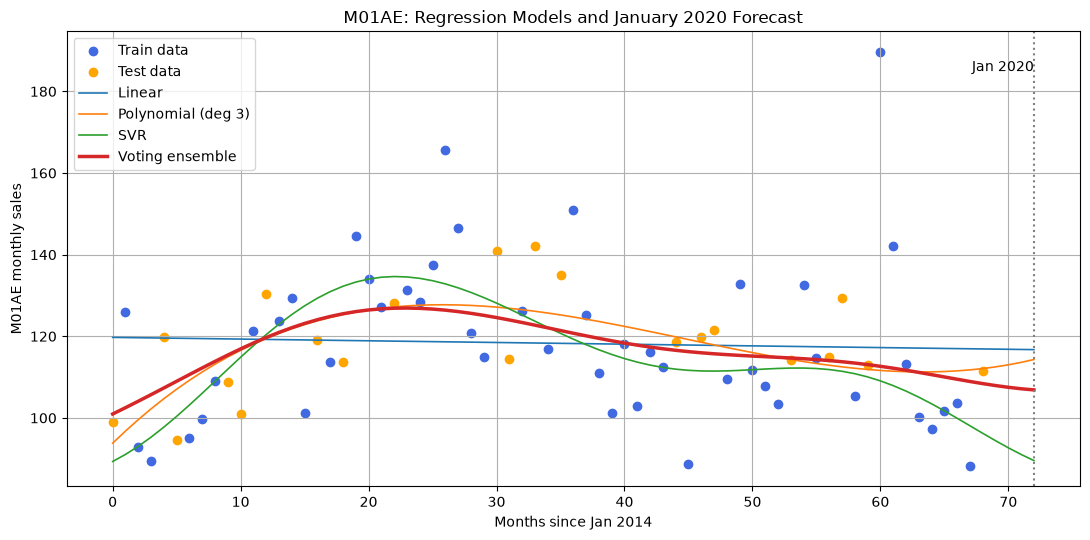

INSIGHT: The ensemble predicts 106.9 units of M01AE for January 2020. Best test R2: Polynomial (deg 3) (0.382).


In [7]:
t_line = np.arange(0, target_t + 1).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(X_train, y_train, color='royalblue', label='Train data')
ax.scatter(X_test, y_test, color='orange', label='Test data')
for name, mdl in models.items():
    ax.plot(t_line, mdl.predict(t_line), label=name, linewidth=2.5 if 'Voting' in name else 1.2)
ax.axvline(target_t, color='grey', linestyle=':'); ax.text(target_t, ax.get_ylim()[1]*0.95, 'Jan 2020', ha='right')
ax.set_xlabel('Months since Jan 2014'); ax.set_ylabel(f'{product} monthly sales')
ax.set_title(f'{product}: Regression Models and January 2020 Forecast'); ax.legend()
plt.tight_layout(); plt.savefig('outputs/p2_forecast.png', dpi=150); plt.show()

v = regResults.loc['Voting ensemble', f'Predicted {product} Jan 2020']
print(f"INSIGHT: The ensemble predicts {v} units of {product} for January 2020. "
      f"Best test R2: {regResults['R2 (test)'].idxmax()} ({regResults['R2 (test)'].max()}).")

## Limitations
- Time alone is a weak predictor. Monthly sales have seasonality that these models ignore, so R² can be low.
- Polynomial models can swing wildly when extrapolating beyond the data.
- A random train/test split lets the model see future months. A fairer test trains on early years and tests on the latest months.
- Try it: replace zero months with the median instead of removing them, and add `Month` as a second input to capture seasonality.